/tmp/ipykernel_874/2983515884.py:10: FutureWarning: YF.download() has changed argument auto_adjust default to True
  loading = yf.download(stocks, start="2022-01-01", end="2026-01-01")
[*********************100%***********************]  5 of 5 completed


for pairIONQ,andVOO,p-value is 0.010538087122521852
for pairTQQQ,andVOO,p-value is 0.00034806664973836805
for pairTQQQ,andJPM,p-value is 0.004463926781703531
for pairVOO,andJPM,p-value is 0.00022009118455502212

Long Entry Dates:
Date
2022-02-23    1
2022-03-07    1
2022-03-14    1
2022-05-09    1
2022-06-13    1
2022-06-14    1
2022-08-26    1
2022-08-29    1
2022-08-30    1
2022-11-03    1
2022-12-15    1
2022-12-16    1
2022-12-19    1
2022-12-20    1
2023-04-25    1
2023-08-17    1
2023-09-21    1
2023-09-26    1
2023-10-25    1
2023-10-26    1
2024-04-04    1
2024-04-15    1
2024-04-16    1
2024-04-17    1
2024-04-18    1
2024-04-19    1
2024-04-22    1
2024-07-24    1
2024-07-25    1
2025-02-27    1
2025-03-03    1
2025-03-10    1
2025-04-03    1
2025-04-04    1
2025-04-07    1
2025-04-08    1
2025-11-20    1
dtype: int64

Short Entry Dates:
Date
2022-07-20   -1
2022-07-21   -1
2022-07-29   -1
2022-08-03   -1
2022-08-04   -1
2023-01-23   -1
2023-02-02   -1
2023-03-16   -1
2023-03

/tmp/ipykernel_874/2983515884.py:86: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


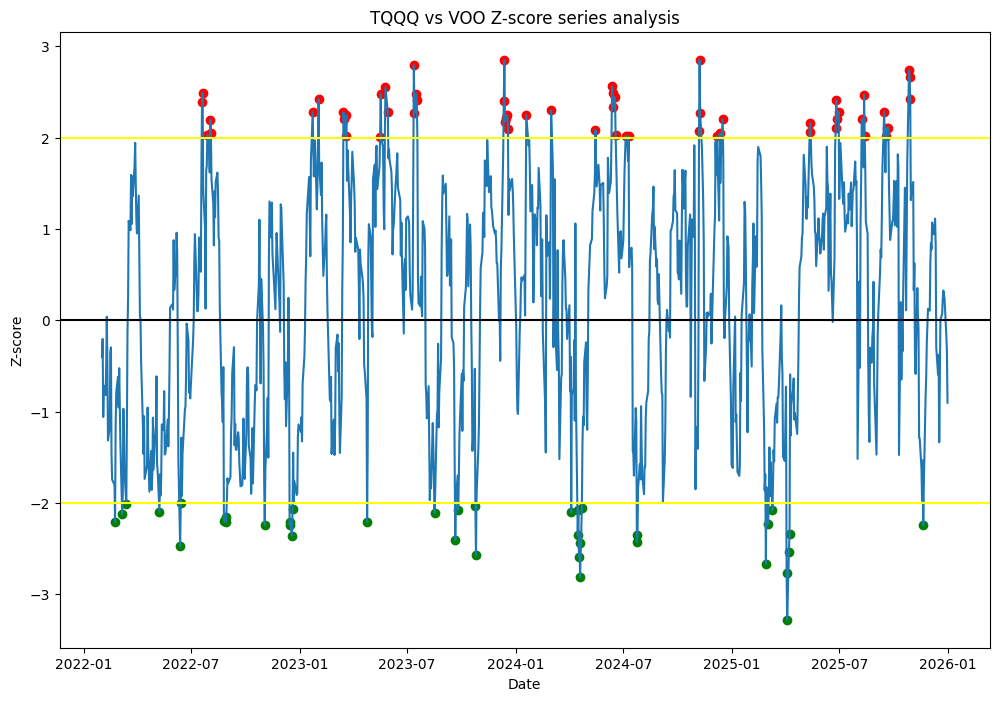

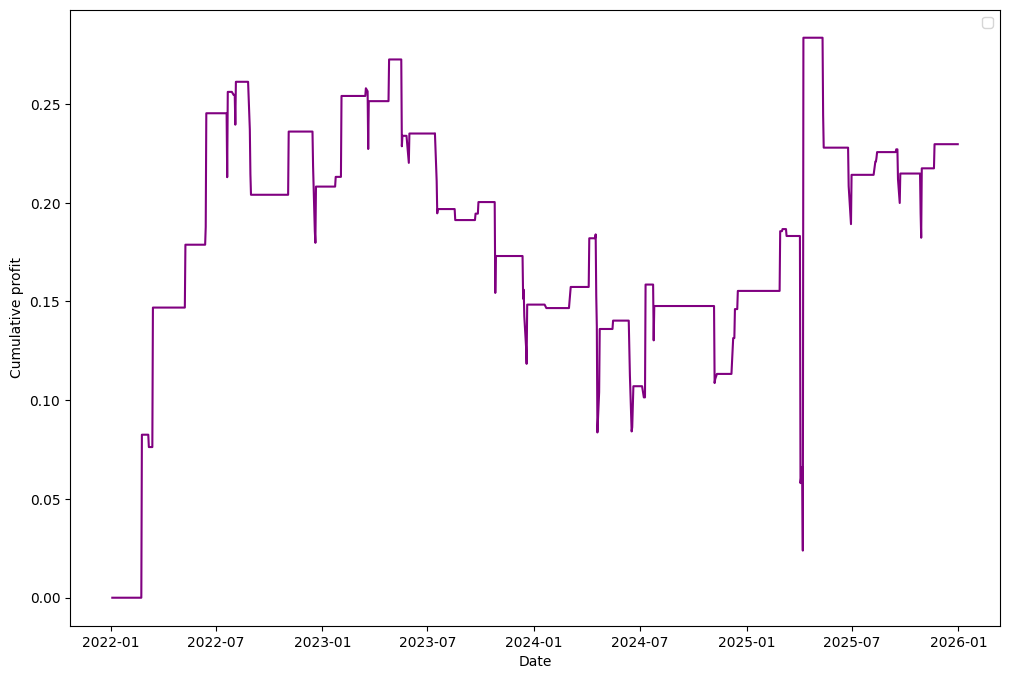

In [44]:
import yfinance as yf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.stattools import coint
import pandas as pd
import matplotlib.pyplot as plt
"""
1. DATA INGESTION & UNIVERSE SELECTION
"""
stocks = ["SPY", "IONQ","TQQQ", "VOO", "JPM"]
loading = yf.download(stocks, start="2022-01-01", end="2026-01-01")
prices = loading["Close"]
"""
2. STATISTICAL COINTEGRATION TEST
"""
# Iterate through all unique pairs to find stationary relationships
for i in range(len(stocks)):
  for j in range(i+1, len(stocks)):
    # Run Engle-Granger cointegration test
    test = coint(prices.iloc[:,i], prices.iloc[:,j])
    # Check if p-value is statistically significant (95% confidence)
    if test[1] < 0.05:
      print(f"for pair{stocks[i]},and{stocks[j]},p-value is {test[1]}")
"""
3. ROLLING Z-SCORE (THE SPREAD)
"""
# Calculate 21-day (1 trading month) rolling mean and standard deviation
spread = prices["TQQQ"]/prices["VOO"]
rolling_mean = spread.rolling(window=21).mean()
rolling_std = spread.rolling(window=21).std()
# Standardize the spread into a Z-score to measure standard deviation breaches
z_score =(spread - rolling_mean)/rolling_std
"""
4. VECTORIZED SIGNAL GENERATION
"""
signals = pd.Series(0,index=z_score.index)
# Trigger Short (-1) when spread is abnormally cheap (<- 2 std dev)
signals[z_score<-2]=1
# Trigger Short (-1) when spread is abnormally expensive (> 2 std dev)
signals[z_score>2]=-1
# Exit position (0) when spread reverts to the historical mean
signals[(0.5>z_score) & (z_score>-0.5)]=0
# Isolate exact entry dates and values for visualization
buy_signals = z_score[signals==1]
sell_signals = z_score[signals==-1]
print(f"\nLong Entry Dates:\n{signals[signals == 1]}")
print(f"\nShort Entry Dates:\n{signals[signals == -1]}")
"""
5. VECTORIZED BACKTESTING (P&L)
"""
change_TQQQ = prices["TQQQ"].pct_change()
change_VOO = prices["VOO"].pct_change()
# Calculate the daily return of holding the long/short spread
spread_return = change_TQQQ - change_VOO
profit_final =spread_return * signals.shift(1)
cumulative_profit = profit_final.cumsum()
print(f"\nFinal Cumulative Profit:\n{cumulative_profit}")
"""
6. RISK & PERFORMANCE METRICS
"""
# Calculate Annualized Sharpe Ratio (Return per unit of risk)
sharpe = profit_final.mean()/profit_final.std() *(252**0.5)
# Calculate Maximum Drawdown (Worst peak-to-trough drop)
drawdown = cumulative_profit - cumulative_profit.cummax()
max_drawdown = drawdown.min()
print(f"\nSharpe ratio:{sharpe:.4f}")
print(f"Maximal drawdown:{max_drawdown:.4f}")
"""
7. VISUALIZATION
"""
# Chart 1: Z-Score and Trade Triggers
plt.figure(figsize=(12,8))
plt.plot(z_score)
plt.scatter(buy_signals.index,buy_signals,color="green",label="Buy points")
plt.scatter(sell_signals.index,sell_signals,color="red",label="Sell points")
plt.axhline(-2,color="yellow",label="-2 std")
plt.axhline(2,color="yellow",label="2 std")
plt.axhline(0,color="black",label="Mean")
plt.xlabel("Date")
plt.ylabel("Z-score")
plt.title("TQQQ vs VOO Z-score series analysis")
# Chart 2: Strategy Equity Curve
plt.figure(figsize=(12,8))
plt.plot(cumulative_profit,color="purple")
plt.xlabel("Date")
plt.ylabel("Cumulative profit")
plt.legend()
plt.show()















